# 03b · Forgery detector v2: tiles on high-resolution templates (Phase 3, Part B — validation only)

**Why a second version.** The v1 whole-image models (notebook 03) reached validation PR-AUC 0.976 but learned
shortcuts, not edits. Forged and genuine *video frames* differ in recording and file format (PNG against JPEG),
so the label could be read without looking at the document. On *templates* the models were close to random, and
Grad-CAM never pointed at the edited field. v2 removes both shortcuts and lets the model see the edit:

1. **Templates only.** Clip frames are left out of forgery work entirely.
2. **Same file treatment for both classes.** Genuine templates were stored at JPEG quality 92 and forged ones at
   75. Every template is converted to RGB, resized so its longest side is exactly **1280 px**, and saved at
   **quality 75**, all through one code path (`ekyc.data.build_cache`).
3. **Tiles.** Each page is cut into overlapping 224 × 224 tiles (stride 112). A tile is labelled forged if it shows
   the edited field, using the annotated box. The model (EfficientNetB0) scores tiles, and a page's score is its
   highest tile score (or the mean of its top 3, chosen on validation). Training-time JPEG re-encoding at random
   qualities (60–95) makes compression traces useless as a cue.
4. **Checks before trusting the numbers.**
   - *Negative control:* tiles of forged pages that do not touch the edit must score like tiles of genuine pages.
     If they score clearly higher, the model still recognises the page, not the edit.
   - *Localisation:* the top-scoring tile should lie on the edit.

   This notebook stops (no tuning) if the document-level validation ROC-AUC is below 0.70 or the negative
   control fails.

**Validation only:** the test split's pages are only counted (their tile numbers come from page sizes); no test
image is read and no test score is computed.

Code: `src/ekyc/data.py` (hi-res cache, JPEG-quality estimate), `src/ekyc/tiles.py` (tile grid, labels, tf.data,
page scores), `models.py`, `evaluation.py`; tests in `tests/test_tiles.py`.

In [1]:
import json
import os
import re
import shutil
import subprocess
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow's C++ info messages

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

from ekyc import config, data, evaluation, models, tiles

keras.utils.set_random_seed(config.SEED)
ROOT = config.PROJECT_ROOT
SMOKE_DIR = None  # None in the real run
REPORT_DIR = Path(SMOKE_DIR) / "reports" if SMOKE_DIR else config.REPORTS_DIR / "phase3"
MODEL_DIR = Path(SMOKE_DIR) / "models" if SMOKE_DIR else ROOT / "models"
PAGES_CSV = Path(SMOKE_DIR) / "pages.csv" if SMOKE_DIR else config.HIRES_MANIFEST_CSV

LONGEST, QUALITY = config.HIRES_LONGEST, config.HIRES_QUALITY  # 1280 px, JPEG quality 75
TILE, STRIDE = config.TILE_SIZE, config.TILE_STRIDE  # 224 px tiles, 112 px apart
BATCH_SIZE = 32
NEGATIVES_PER_PAGE = 4 if SMOKE_DIR else 16  # clean tiles drawn at random from every page, every epoch
MONITOR = "val_pr_auc"  # tile-level PR-AUC on all labelled validation tiles
STAGE1 = {"learning_rate": 1e-3, "max_epochs": 1 if SMOKE_DIR else 5, "patience": 3}
STAGE2 = {"learning_rate": 3e-5, "max_epochs": 1 if SMOKE_DIR else 10, "patience": 3, "reduce_lr_patience": 1,
          "unfreeze_layers": 75}
MIN_DOC_ROC_AUC = 0.70  # stop rule 1: document-level validation ROC-AUC must reach this
MAX_CONTROL_AUC = 0.60  # stop rule 2: off-edit tiles of forged pages vs genuine tiles must stay below this

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # validated colour-blind-safe order; always with a legend


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)


def peak_memory_gb():
    """Peak physical memory of this notebook process (includes GPU buffers, which share RAM on Apple Silicon)."""
    out = subprocess.run(["footprint", "-p", str(os.getpid())], capture_output=True, text=True).stdout
    value, unit = re.search(r"phys_footprint_peak:\s*([\d.]+)\s*(KB|MB|GB)", out).groups()
    return float(value) * {"KB": 1 / 1024**2, "MB": 1 / 1024, "GB": 1}[unit]


def swap_used_gb():
    out = subprocess.run(["sysctl", "-n", "vm.swapusage"], capture_output=True, text=True).stdout
    return float(re.search(r"used = ([\d.]+)M", out).group(1)) / 1024


for folder in (REPORT_DIR, MODEL_DIR, PAGES_CSV.parent):
    folder.mkdir(parents=True, exist_ok=True)
notebook_start = time.perf_counter()
tf.reduce_sum(tf.ones((2, 2))).numpy()  # first GPU operation: TensorFlow sets up the Metal device here
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
print(f"pages: longest side {LONGEST} px, JPEG quality {QUALITY} | tiles {TILE} px, stride {STRIDE} px | "
      f"batch {BATCH_SIZE}, {NEGATIVES_PER_PAGE} clean tiles per page per epoch")
print(f"stage 1 {STAGE1}\nstage 2 {STAGE2}\nstop rules: document ROC-AUC >= {MIN_DOC_ROC_AUC}, "
      f"negative-control AUC <= {MAX_CONTROL_AUC}")
print(f"swap in use at start: {swap_used_gb():.1f} GB" + (" | SMOKE TEST" if SMOKE_DIR else ""))

TensorFlow 2.18.1 | Keras 3.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
pages: longest side 1280 px, JPEG quality 75 | tiles 224 px, stride 112 px | batch 32, 16 clean tiles per page per epoch
stage 1 {'learning_rate': 0.001, 'max_epochs': 5, 'patience': 3}
stage 2 {'learning_rate': 3e-05, 'max_epochs': 10, 'patience': 3, 'reduce_lr_patience': 1, 'unfreeze_layers': 75}
stop rules: document ROC-AUC >= 0.7, negative-control AUC <= 0.6
swap in use at start: 16.1 GB


I0000 00:00:1794816140.818145 35785057 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794816140.818254 35785057 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


**Setup.** All settings are in one place. The epoch limits come from a benchmark run before this notebook:
about 3.5 min of training and 2.6 min of validation per epoch, so the whole run fits in roughly two hours. The
two stop rules are fixed here, before any result is seen, so they cannot be adjusted to fit the outcome. Stage 2
uses a learning rate of 0.00003 instead of v1's 0.00001, because it unfreezes more layers (the top 75: blocks 6
and 7) on a smaller set of images. Clipping, frozen BatchNormalization and `TerminateOnNaN` protect against the
NaN failure seen in Phase 3A.

In [2]:
manifest = pd.read_csv(config.MANIFEST_CSV)
# Templates only: clip frames are excluded from forgery work (v1 finding: their label equals the recording).
templates = manifest[manifest["source"] == "template"].drop(columns=["cache_path"])
if SMOKE_DIR:  # a few pages per split and label
    templates = templates.groupby(["split", "label"]).head(6)
hires, written = data.build_cache(templates, longest=LONGEST, quality=QUALITY, cache_dir=config.HIRES_DIR,
                                  enlarge=True, path_column="hires_path")
pages = tiles.build_pages_table(hires, pd.read_csv(config.FIELDS_GT_CSV))
pages["class"] = pages["label"].map({0: "genuine", 1: "forged"})
pages.to_csv(PAGES_CSV, index=False)
print(f"{len(pages)} template pages; hi-res files written in this run: {written} "
      f"(the others were already there from an earlier run of the same code)")
display(pd.crosstab(pages["split"], pages["class"]))
display(pages.groupby("doc_type")[["orig_width", "orig_height", "hires_width", "hires_height"]].first())
print("Crop_and_Replace pages with an 'ignore' box (donor field differs from the altered field):",
      int(pages["ignore_x"].notna().sum()))

resizing:   0%|          | 0/2222 [00:00<?, ?img/s]

resizing: 100%|██████████| 2222/2222 [00:00<00:00, 5171.99img/s]

2222 template pages; hi-res files written in this run: 0 (the others were already there from an earlier run of the same code)


class,forged,genuine
split,,
test,190,148
train,853,702
val,179,150


,orig_width,orig_height,hires_width,hires_height
doc_type,,,,
alb_id,2167,1360,1280,803
aze_passport,2167,1525,1280,901
esp_id,1327,827,1280,798
est_id,929,580,1280,799
fin_id,931,584,1280,803
grc_passport,1136,803,1280,905
lva_passport,2167,1521,1280,898
rus_internalpassport,1519,1069,1280,901
srb_passport,2163,1488,1280,881


Crop_and_Replace pages with an 'ignore' box (donor field differs from the altered field): 18


<!-- id: pages -->
PENDING

In [3]:
forged_pages = pages[pages["label"] == 1]
heights = forged_pages.groupby("doc_type")["edit_h"].agg(
    median="median", smallest="min", share_at_least_25px=lambda h: (h >= 25).mean())
heights.loc["all"] = [forged_pages["edit_h"].median(), forged_pages["edit_h"].min(), (forged_pages["edit_h"] >= 25).mean()]
print("Height of the altered field in hi-res pixels (forged pages):")
display(heights.round(2))

pages["quality before"] = [data.estimate_jpeg_quality(ROOT / p) for p in pages["image_path"]]  # header only
pages["quality after"] = [data.estimate_jpeg_quality(ROOT / p) for p in pages["hires_path"]]
pages["file kB"] = [os.path.getsize(ROOT / p) / 1024 for p in pages["hires_path"]]
print("Estimated JPEG quality (from each file's quantisation table) and hi-res file size, per class:")
display(pages.groupby("class").agg(quality_before_min=("quality before", "min"), quality_before_max=("quality before", "max"),
                                   quality_after_min=("quality after", "min"), quality_after_max=("quality after", "max"),
                                   median_file_kB=("file kB", "median")).round(1))
sizes = pages.pivot_table(index="doc_type", columns="class", values="file kB", aggfunc="median")
sizes["forged / genuine"] = sizes["forged"] / sizes["genuine"]
print("Median file size per document type (pages of one type share their layout, so sizes are comparable):")
display(sizes.round(3))

Height of the altered field in hi-res pixels (forged pages):


,median,smallest,share_at_least_25px
doc_type,,,
alb_id,30.11,25.39,1.00
aze_passport,21.86,16.54,0.25
esp_id,28.95,27.98,1.00
est_id,28.93,26.17,1.00
fin_id,30.25,24.75,0.93
grc_passport,20.29,19.16,0.15
lva_passport,25.98,21.25,0.59
rus_internalpassport,26.13,23.60,0.60
srb_passport,20.13,18.35,0.06


Estimated JPEG quality (from each file's quantisation table) and hi-res file size, per class:


,quality_before_min,quality_before_max,quality_after_min,quality_after_max,median_file_kB
class,,,,,
forged,75,75,75,75,194.5
genuine,92,92,75,75,198.3


Median file size per document type (pages of one type share their layout, so sizes are comparable):


class,forged,genuine,forged / genuine
doc_type,,,
alb_id,253.165,253.863,0.997
aze_passport,193.122,193.205,1.000
esp_id,177.505,179.707,0.988
est_id,110.064,111.466,0.987
fin_id,195.791,204.998,0.955
grc_passport,228.870,227.556,1.006
lva_passport,229.982,229.615,1.002
rus_internalpassport,149.812,148.542,1.009
srb_passport,275.091,273.731,1.005


<!-- id: quality -->
PENDING

In [4]:
split_pages = {s: pages[pages["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
split_tiles = {s: tiles.build_tile_table(p) for s, p in split_pages.items()}  # geometry + boxes only, no pixels
counts = pd.DataFrame({s: t["label"].value_counts() for s, t in split_tiles.items()}).T.fillna(0).astype(int)
counts = counts.rename(columns={1: "1 = shows the edit", 0: "0 = clean", -1: "-1 = ignored"})
counts["tiles per page"] = (counts.sum(axis=1) / pd.Series({s: len(p) for s, p in split_pages.items()})).round(1)
display(counts)

train_pages, train_tiles = split_pages["train"], split_tiles["train"]
val_pages, val_tiles = split_pages["val"], split_tiles["val"]
assert val_tiles.equals(val_tiles.sort_values(["page", "y", "x"])), "scores are matched to tiles by order"
per_epoch = tiles.epoch_tile_counts(train_tiles, NEGATIVES_PER_PAGE)
n_epoch = sum(per_epoch.values())
class_weight = {c: n_epoch / (2 * n) for c, n in per_epoch.items()}
print(f"one training epoch = all {per_epoch[1]:,} edit tiles + {per_epoch[0]:,} clean tiles "
      f"({NEGATIVES_PER_PAGE} random ones per page, new ones every epoch)")
print("class weights from these tile counts:", {c: round(w, 3) for c, w in class_weight.items()})
train_ds = tiles.make_tile_dataset(train_pages, train_tiles, BATCH_SIZE, training=True,
                                   negatives_per_page=NEGATIVES_PER_PAGE)
val_ds = tiles.make_tile_dataset(val_pages, val_tiles, 64)  # every validation tile labelled 0 or 1

label,0 = clean,1 = shows the edit,-1 = ignored,tiles per page
train,118729,5702,2102,81.4
val,25214,1260,366,81.6
test,25882,1243,430,81.5


one training epoch = all 5,702 edit tiles + 24,880 clean tiles (16 random ones per page, new ones every epoch)
class weights from these tile counts: {0: 0.615, 1: 2.682}


<!-- id: tiles -->
PENDING

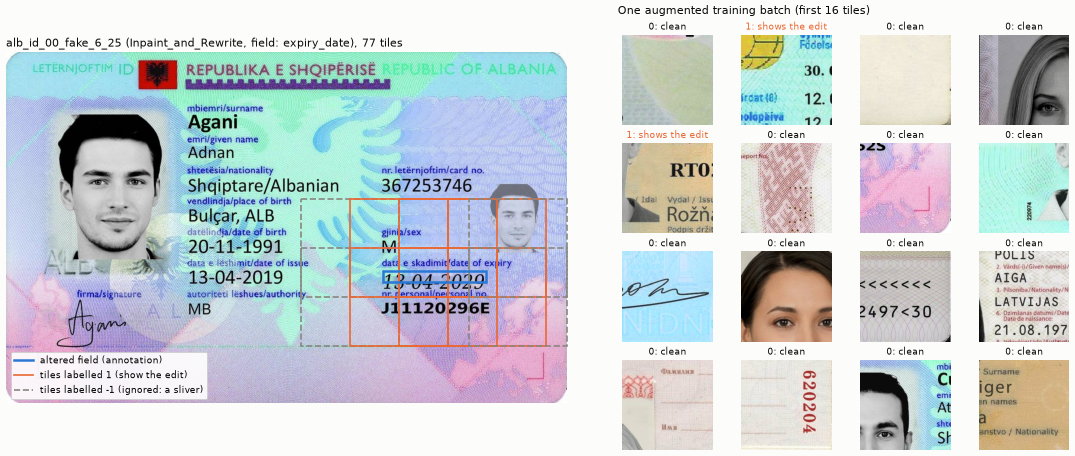

batch (32, 224, 224, 3), float32, pixel range 0-255, 3 of 32 tiles labelled 1


In [5]:
# Left: the tile labels of one forged training page. Right: one augmented training batch as the model sees it.
example = train_pages[train_pages["label"] == 1].sort_values("fake_name").iloc[0]
page_tiles = train_tiles[train_tiles["page"] == example.name]
fig = plt.figure(figsize=(18, 7.5), dpi=60, facecolor=SURFACE, layout="constrained")
left, right = fig.subfigures(1, 2, width_ratios=[1.25, 1])
ax = left.subplots()
with Image.open(ROOT / example["hires_path"]) as image:
    ax.imshow(image)
for row in page_tiles[page_tiles["label"] != 0].itertuples():
    color = ORANGE if row.label == 1 else MUTED
    ax.add_patch(Rectangle((row.x, row.y), TILE, TILE, fill=False, edgecolor=color, linewidth=2,
                           linestyle="-" if row.label == 1 else "--"))
ax.add_patch(Rectangle((example["edit_x"], example["edit_y"]), example["edit_w"], example["edit_h"],
                       fill=False, edgecolor=BLUE, linewidth=3))
ax.plot([], [], color=BLUE, linewidth=3, label="altered field (annotation)")
ax.plot([], [], color=ORANGE, linewidth=2, label="tiles labelled 1 (show the edit)")
ax.plot([], [], color=MUTED, linewidth=2, linestyle="--", label="tiles labelled -1 (ignored: a sliver)")
ax.legend(loc="lower left", fontsize=11, framealpha=0.9)
ax.set_title(f"{example['fake_name']} ({example['ctype']}, field: {example['altered_field']}), "
             f"{len(page_tiles)} tiles", loc="left", color=INK, fontsize=13)
ax.axis("off")

images, labels = next(iter(train_ds))
axes = right.subplots(4, 4)
for a, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    a.imshow(image.astype("uint8"))
    a.set_title("1: shows the edit" if label == 1 else "0: clean", fontsize=11, color=ORANGE if label == 1 else INK)
    a.axis("off")
right.suptitle("One augmented training batch (first 16 tiles)", x=0.02, ha="left", color=INK, fontsize=13)
fig.savefig(REPORT_DIR / "forgery_v2_tiles_check.png", dpi=70, facecolor=SURFACE)
plt.show()
print(f"batch {tuple(images.shape)}, {images.dtype.name}, pixel range {images.numpy().min():.0f}-{images.numpy().max():.0f}, "
      f"{int(labels.numpy().sum())} of {len(labels)} tiles labelled 1")

<!-- id: tiles_check -->
PENDING

In [6]:
model, backbone = models.build_forgery_detector(TILE)  # EfficientNetB0 (ImageNet) + sigmoid head, 224 px input
models.compile_forgery_model(model, STAGE1["learning_rate"])  # Adam with clipnorm=1.0, PR-AUC + ROC-AUC
print(f"EfficientNetB0 tile model: {model.count_params():,} parameters, "
      f"{int(sum(np.prod(w.shape) for w in model.trainable_weights)):,} trainable in stage 1 (the head)\n")
callbacks_s1 = models.training_callbacks(MODEL_DIR / "forgery_tiles_stage1.keras", REPORT_DIR / "forgery_v2_stage1_log.csv",
                                         STAGE1["patience"], MONITOR, "max")
# shuffle=False: the tf.data pipeline already reshuffles pages and tiles every epoch.
history_s1 = model.fit(train_ds, validation_data=val_ds, epochs=STAGE1["max_epochs"], class_weight=class_weight,
                       callbacks=callbacks_s1, shuffle=False, verbose=2)
s1_seconds = callbacks_s1[-1].seconds
print(f"\nstage 1: {len(s1_seconds)} epochs in {sum(s1_seconds) / 60:.1f} min, {np.mean(s1_seconds) / 60:.1f} min per epoch; "
      f"best val tile PR-AUC {max(history_s1.history['val_pr_auc']):.4f}")

EfficientNetB0 tile model: 4,050,852 parameters, 1,281 trainable in stage 1 (the head)

Epoch 1/5


956/956 - 311s - 326ms/step - loss: 0.5498 - pr_auc: 0.4096 - roc_auc: 0.7876 - val_loss: 0.4563 - val_pr_auc: 0.1715 - val_roc_auc: 0.8222


Epoch 2/5


956/956 - 352s - 368ms/step - loss: 0.5085 - pr_auc: 0.4673 - roc_auc: 0.8211 - val_loss: 0.5040 - val_pr_auc: 0.2001 - val_roc_auc: 0.8357


Epoch 3/5


956/956 - 391s - 409ms/step - loss: 0.5005 - pr_auc: 0.4857 - roc_auc: 0.8274 - val_loss: 0.4709 - val_pr_auc: 0.2137 - val_roc_auc: 0.8418


... (2 outputs left out)

Epoch 5/5


956/956 - 506s - 530ms/step - loss: 0.4986 - pr_auc: 0.4781 - roc_auc: 0.8286 - val_loss: 0.4720 - val_pr_auc: 0.2062 - val_roc_auc: 0.8455


Restoring model weights from the end of the best epoch: 3.



stage 1: 5 epochs in 30.6 min, 6.1 min per epoch; best val tile PR-AUC 0.2137


<!-- id: stage1 -->
PENDING

In [7]:
n_unfrozen = models.unfreeze_top_layers(backbone, STAGE2["unfreeze_layers"])
models.compile_forgery_model(model, STAGE2["learning_rate"])  # re-compile after changing `trainable`
n_bn_trainable = sum(l.trainable for l in backbone.layers if isinstance(l, keras.layers.BatchNormalization))
print(f"unfrozen {n_unfrozen} of the top {STAGE2['unfreeze_layers']} backbone layers; trainable BatchNormalization "
      f"layers: {n_bn_trainable}; trainable parameters now {int(sum(np.prod(w.shape) for w in model.trainable_weights)):,}\n")
callbacks_s2 = models.training_callbacks(MODEL_DIR / "forgery_tiles_stage2.keras", REPORT_DIR / "forgery_v2_stage2_log.csv",
                                         STAGE2["patience"], MONITOR, "max", STAGE2["reduce_lr_patience"])
history_s2 = model.fit(train_ds, validation_data=val_ds, epochs=STAGE2["max_epochs"], class_weight=class_weight,
                       callbacks=callbacks_s2, shuffle=False, verbose=2)
s2_seconds = callbacks_s2[-1].seconds
print(f"\nstage 2: {len(s2_seconds)} epochs in {sum(s2_seconds) / 60:.1f} min, {np.mean(s2_seconds) / 60:.1f} min per epoch; "
      f"best val tile PR-AUC {max(history_s2.history['val_pr_auc']):.4f}")

unfrozen 59 of the top 75 backbone layers; trainable BatchNormalization layers: 0; trainable parameters now 3,055,901



Epoch 1/10


956/956 - 662s - 692ms/step - loss: 0.4295 - pr_auc: 0.6167 - roc_auc: 0.8760 - val_loss: 0.3725 - val_pr_auc: 0.4883 - val_roc_auc: 0.9091 - learning_rate: 3.0000e-05


Epoch 2/10


956/956 - 790s - 826ms/step - loss: 0.3357 - pr_auc: 0.7724 - roc_auc: 0.9277 - val_loss: 0.2957 - val_pr_auc: 0.6176 - val_roc_auc: 0.9319 - learning_rate: 3.0000e-05


Epoch 3/10


... (15 outputs left out)


Epoch 10: ReduceLROnPlateau reducing learning rate to 7.499999810534064e-06.


956/956 - 484s - 507ms/step - loss: 0.1542 - pr_auc: 0.9549 - roc_auc: 0.9855 - val_loss: 0.0921 - val_pr_auc: 0.8663 - val_roc_auc: 0.9606 - learning_rate: 1.5000e-05


Restoring model weights from the end of the best epoch: 9.



stage 2: 10 epochs in 102.9 min, 10.3 min per epoch; best val tile PR-AUC 0.8741


<!-- id: stage2 -->
PENDING

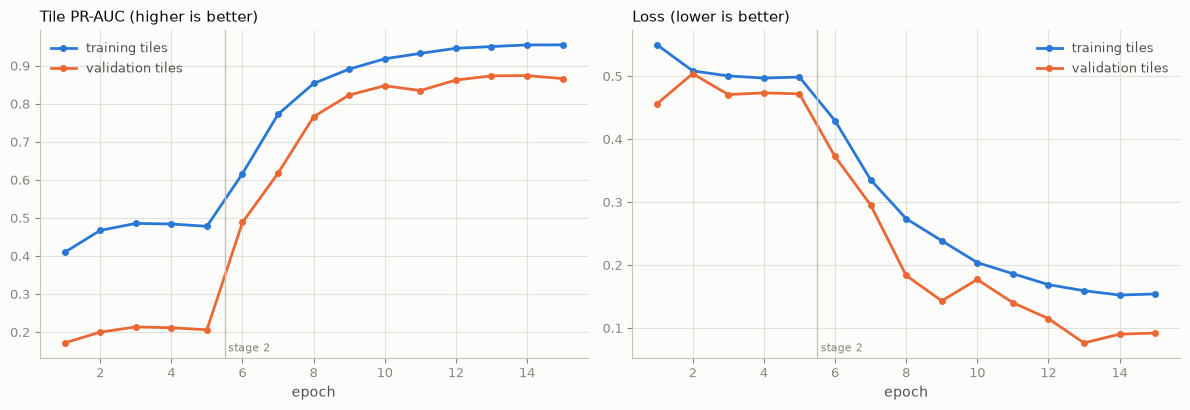

,loss,pr_auc,val_loss,val_pr_auc,val_roc_auc
1,0.5498,0.4096,0.4563,0.1715,0.8222
2,0.5085,0.4673,0.5040,0.2001,0.8357
3,0.5005,0.4857,0.4709,0.2137,0.8418
4,0.4970,0.4842,0.4735,0.2116,0.8387
5,0.4986,0.4781,0.4720,0.2062,0.8455
6,0.4295,0.6167,0.3725,0.4883,0.9091
7,0.3357,0.7724,0.2957,0.6176,0.9319
8,0.2739,0.8535,0.1836,0.7661,0.9467
9,0.2388,0.8912,0.1433,0.8231,0.9624
10,0.2041,0.9183,0.1772,0.8474,0.9664


In [8]:
logs = {name: pd.read_csv(REPORT_DIR / f"forgery_v2_{name}_log.csv") for name in ("stage1", "stage2")}
log = pd.concat(logs.values(), ignore_index=True)
epochs = np.arange(1, len(log) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100, facecolor=SURFACE)
for ax, (train_col, val_col, title) in zip(axes, [("pr_auc", "val_pr_auc", "Tile PR-AUC (higher is better)"),
                                                  ("loss", "val_loss", "Loss (lower is better)")]):
    ax.plot(epochs, log[train_col], color=BLUE, linewidth=2, marker="o", markersize=4, label="training tiles")
    ax.plot(epochs, log[val_col], color=ORANGE, linewidth=2, marker="o", markersize=4, label="validation tiles")
    ax.axvline(len(logs["stage1"]) + 0.5, color=AXIS, linewidth=1)
    ax.text(len(logs["stage1"]) + 0.6, 0.02, "stage 2", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8)
    style(ax, title)
    ax.set_xlabel("epoch")
    ax.legend(frameon=False, labelcolor=INK_2, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_v2_training_curves.png", dpi=150, facecolor=SURFACE)
plt.show()
display(log[["loss", "pr_auc", "val_loss", "val_pr_auc", "val_roc_auc"]].set_index(epochs).round(4))

<!-- id: curves -->
PENDING

In [9]:
# Score EVERY validation tile (including the ignored ones) with each saved checkpoint; tiles keep table order.
all_val_ds = tiles.make_tile_dataset(val_pages, val_tiles, 64, labelled_only=False)
checkpoints = {"stage 1": "forgery_tiles_stage1.keras", "stage 2": "forgery_tiles_stage2.keras"}
labelled = (val_tiles["label"] >= 0).to_numpy()
tile_scores, tile_ranking = {}, {}
for name, file in checkpoints.items():
    if not (MODEL_DIR / file).exists():  # e.g. a stage stopped by TerminateOnNaN before its first checkpoint
        print(f"{name}: no checkpoint saved, skipped")
        continue
    scores = keras.models.load_model(MODEL_DIR / file).predict(all_val_ds, verbose=0)[:, 0]
    assert len(scores) == len(val_tiles)
    tile_scores[name] = scores
    y_tile, s_tile = val_tiles["label"].to_numpy()[labelled], scores[labelled]
    tile_ranking[name] = {"tile PR-AUC": average_precision_score(y_tile, s_tile),
                          "tile ROC-AUC": roc_auc_score(y_tile, s_tile)}
tile_ranking = pd.DataFrame(tile_ranking).T
display(tile_ranking.round(4))
choice = tile_ranking["tile PR-AUC"].idxmax()
val_tiles["score"] = tile_scores[choice]
print(f"chosen checkpoint: {choice} ({checkpoints[choice]}); "
      f"random guessing would give tile PR-AUC {val_tiles.loc[labelled, 'label'].mean():.3f} (share of edit tiles)")

,tile PR-AUC,tile ROC-AUC
stage 1,0.2140,0.8418
stage 2,0.8744,0.9633


chosen checkpoint: stage 2 (forgery_tiles_stage2.keras); random guessing would give tile PR-AUC 0.048 (share of edit tiles)


<!-- id: tile_choice -->
PENDING

In [10]:
y_doc = val_pages["label"].to_numpy()
page_score = {how: tiles.page_scores(val_tiles, how=how).reindex(range(len(val_pages))).to_numpy()
              for how in ("max", "top3")}
aggregation = pd.DataFrame({how: evaluation.ranking_scores(y_doc, s) for how, s in page_score.items()}).T
aggregation.index = ["highest tile (max)", "mean of top 3 tiles (top3)"]
display(aggregation.round(4))
AGGREGATION = max(page_score, key=lambda how: evaluation.ranking_scores(y_doc, page_score[how])["pr_auc"])
val_pages["score"] = page_score[AGGREGATION]
doc_ranking = evaluation.ranking_scores(y_doc, val_pages["score"])
gate_roc = doc_ranking["roc_auc"] >= MIN_DOC_ROC_AUC
print(f"page score = {AGGREGATION} (chosen on validation PR-AUC). Random guessing: PR-AUC {y_doc.mean():.3f}, ROC-AUC 0.5")
print(f"STOP RULE 1, document ROC-AUC {doc_ranking['roc_auc']:.3f} >= {MIN_DOC_ROC_AUC}: {'PASS' if gate_roc else 'FAIL'}")

,pr_auc,roc_auc
highest tile (max),0.9786,0.9678
mean of top 3 tiles (top3),0.9825,0.9737


page score = top3 (chosen on validation PR-AUC). Random guessing: PR-AUC 0.544, ROC-AUC 0.5
STOP RULE 1, document ROC-AUC 0.974 >= 0.7: PASS


<!-- id: aggregation -->
PENDING

,tiles,median,mean,90th percentile,share > 0.5,AUC vs (a)
(a) genuine pages: all tiles,12221.0,0.0054,0.0546,0.1803,0.0116,NaN
(b) forged pages: tiles not touching the edit,12993.0,0.0044,0.0583,0.1983,0.0195,0.4899
(c) forged pages: tiles at least 112 px from the edit,10488.0,0.0038,0.0517,0.1614,0.0177,0.4736
(d) forged pages: tiles showing the edit (label 1),1260.0,0.9996,0.8312,1.0000,0.8357,0.9632


document ROC-AUC with the edit tiles hidden: 0.583 (with them: 0.974)
STOP RULE 2, AUC (b) vs (a) = 0.490 <= 0.6: PASS


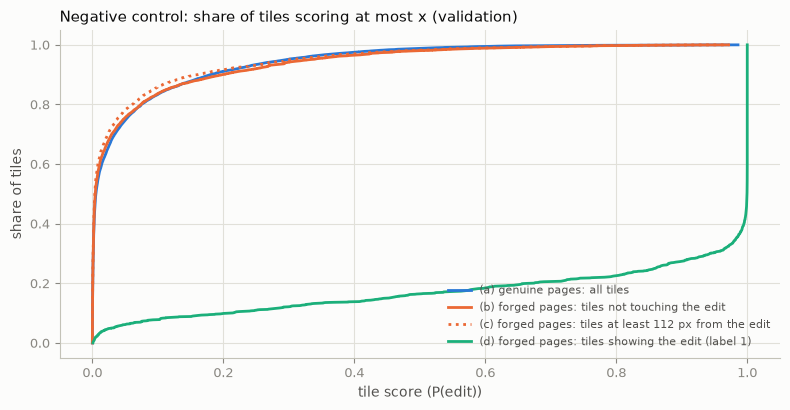

In [11]:
# NEGATIVE CONTROL: does the model score the PAGE (shortcut) or the EDIT?
page_is_forged = y_doc[val_tiles["page"]] == 1
groups = {
    "(a) genuine pages: all tiles": ~page_is_forged,
    "(b) forged pages: tiles not touching the edit": page_is_forged & (val_tiles["label"] == 0).to_numpy(),
    "(c) forged pages: tiles at least 112 px from the edit": page_is_forged & (val_tiles["label"] == 0).to_numpy()
                                                             & val_tiles["far_from_edit"].to_numpy(),
    "(d) forged pages: tiles showing the edit (label 1)": (val_tiles["label"] == 1).to_numpy(),
}
reference = val_tiles.loc[groups["(a) genuine pages: all tiles"], "score"].to_numpy()
rows = {}
for name, mask in groups.items():
    s = val_tiles.loc[mask, "score"].to_numpy()
    both = np.concatenate([reference, s])
    is_group = np.concatenate([np.zeros(len(reference)), np.ones(len(s))])
    rows[name] = {"tiles": len(s), "median": np.median(s), "mean": s.mean(), "90th percentile": np.quantile(s, 0.9),
                  "share > 0.5": (s > 0.5).mean(),
                  "AUC vs (a)": np.nan if name.startswith("(a)") else roc_auc_score(is_group, both)}
control = pd.DataFrame(rows).T
display(control.round(4))
control_auc = control.loc["(b) forged pages: tiles not touching the edit", "AUC vs (a)"]
gate_control = control_auc <= MAX_CONTROL_AUC

# Page-level version: judge forged pages WITHOUT their edit tiles (only label-0 tiles), genuine pages with all tiles.
hidden = val_tiles[~page_is_forged | (val_tiles["label"] == 0).to_numpy()]
hidden_scores = tiles.page_scores(hidden, how=AGGREGATION).reindex(range(len(val_pages))).to_numpy()
hidden_roc = roc_auc_score(y_doc, hidden_scores)
print(f"document ROC-AUC with the edit tiles hidden: {hidden_roc:.3f} (with them: {doc_ranking['roc_auc']:.3f})")
print(f"STOP RULE 2, AUC (b) vs (a) = {control_auc:.3f} <= {MAX_CONTROL_AUC}: {'PASS' if gate_control else 'FAIL'}")

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=100, facecolor=SURFACE)
for (name, mask), color, dash in zip(groups.items(), (BLUE, ORANGE, ORANGE, AQUA), ("-", "-", ":", "-")):
    s = np.sort(val_tiles.loc[mask, "score"].to_numpy())
    ax.plot(s, np.arange(1, len(s) + 1) / len(s), color=color, linestyle=dash, linewidth=2, label=name)
style(ax, "Negative control: share of tiles scoring at most x (validation)")
ax.set(xlabel="tile score (P(edit))", ylabel="share of tiles")
ax.legend(frameon=False, labelcolor=INK_2, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_v2_negative_control.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: control -->
PENDING

In [12]:
thresholds = {"recall >= 0.90": evaluation.threshold_for_recall(y_doc, val_pages["score"], 0.90),
              "F1-optimal": evaluation.f1_optimal_threshold(y_doc, val_pages["score"])}
threshold_table = pd.DataFrame(thresholds).T
threshold_table.to_csv(REPORT_DIR / "forgery_v2_thresholds_val.csv")
display(threshold_table.round(4))
display(pd.concat({rule: evaluation.confusion_at(y_doc, val_pages["score"], t["threshold"])
                   for rule, t in thresholds.items()}, axis=1))

,threshold,precision,recall,f1
recall >= 0.90,0.7408,0.9702,0.9106,NaN
F1-optimal,0.6646,0.9540,0.9274,0.9405


recall >= 0.90                         F1-optimal                 
        predicted genuine predicted forged predicted genuine predicted forged
genuine               145                5               142                8
forged                 16              163                13              166

<!-- id: thresholds -->
PENDING

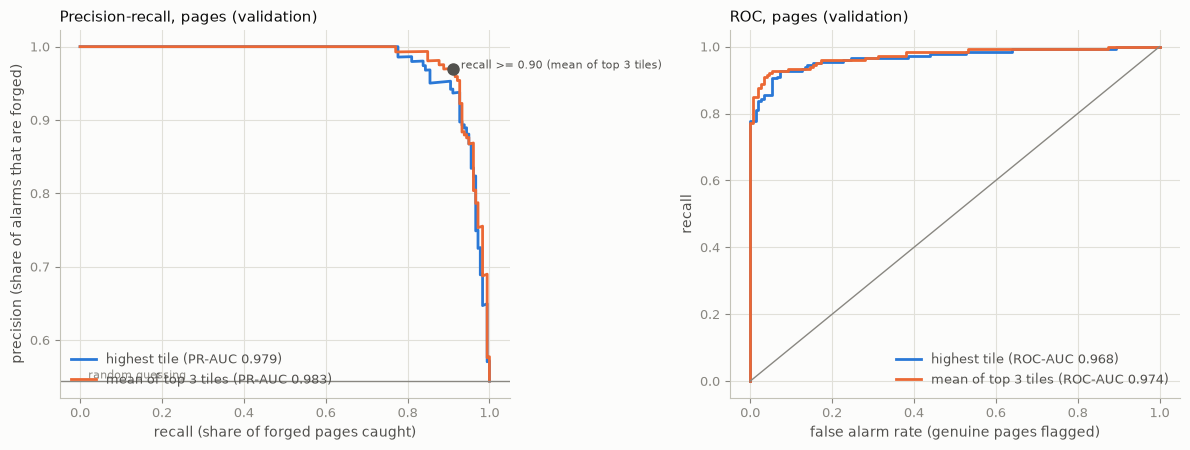

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=100, facecolor=SURFACE)
labels = {"max": "highest tile", "top3": "mean of top 3 tiles"}
for (how, s), color in zip(page_score.items(), (BLUE, ORANGE)):
    r = evaluation.ranking_scores(y_doc, s)
    precision, recall, _ = precision_recall_curve(y_doc, s)
    axes[0].plot(recall, precision, color=color, linewidth=2, label=f"{labels[how]} (PR-AUC {r['pr_auc']:.3f})")
    fpr, tpr, _ = roc_curve(y_doc, s)
    axes[1].plot(fpr, tpr, color=color, linewidth=2, label=f"{labels[how]} (ROC-AUC {r['roc_auc']:.3f})")
t = thresholds["recall >= 0.90"]
axes[0].plot(t["recall"], t["precision"], "o", color=INK_2, markersize=8)
axes[0].annotate(f"  recall >= 0.90 ({labels[AGGREGATION]})", (t["recall"], t["precision"]), color=INK_2, fontsize=8)
axes[0].axhline(y_doc.mean(), color=MUTED, linewidth=1)
axes[0].text(0.01, y_doc.mean(), " random guessing", color=MUTED, fontsize=8, va="bottom")
axes[1].plot([0, 1], [0, 1], color=MUTED, linewidth=1)
style(axes[0], "Precision-recall, pages (validation)")
style(axes[1], "ROC, pages (validation)")
axes[0].set(xlabel="recall (share of forged pages caught)", ylabel="precision (share of alarms that are forged)")
axes[1].set(xlabel="false alarm rate (genuine pages flagged)", ylabel="recall")
for ax in axes:
    ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower left" if ax is axes[0] else "lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_v2_pr_roc_val.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: curves_pr -->
PENDING

In [14]:
threshold = thresholds["recall >= 0.90"]["threshold"]
breakdowns = {}
for by in ("ctype", "doc_type", "altered_field"):
    table = evaluation.breakdown(val_pages, by, threshold)
    if by in ("ctype", "altered_field"):  # forged pages only: recall is the meaningful number
        table = table[["forged", "recall"]]
    breakdowns[by] = table
    table.to_csv(REPORT_DIR / f"forgery_v2_breakdown_{by}_val.csv")
print(f"All breakdowns at the recall >= 0.90 threshold ({threshold:.4f}), validation pages.")
for by in ("ctype", "doc_type"):
    display(breakdowns[by].round(3))
display(breakdowns["altered_field"].sort_values("forged", ascending=False).round(3))

All breakdowns at the recall >= 0.90 threshold (0.7408), validation pages.


,forged,recall
ctype,,
Crop_and_Replace,22.0,0.409
Inpaint_and_Rewrite,157.0,0.981


,images,forged,recall,false_alarm,precision,pr_auc
doc_type,,,,,,
alb_id,28.0,14.0,1.000,0.000,1.000,1.000
aze_passport,22.0,9.0,1.000,0.077,0.900,0.989
esp_id,29.0,15.0,1.000,0.071,0.938,1.000
est_id,27.0,13.0,0.923,0.000,1.000,1.000
fin_id,33.0,18.0,0.833,0.000,1.000,1.000
grc_passport,42.0,26.0,0.962,0.062,0.962,0.991
lva_passport,37.0,20.0,0.850,0.000,1.000,0.987
rus_internalpassport,36.0,21.0,0.905,0.133,0.905,0.987
srb_passport,37.0,20.0,0.750,0.000,1.000,0.953


,forged,recall
altered_field,,
gender,20.0,0.900
name,16.0,0.750
expiry_date,15.0,0.933
surname,14.0,1.000
birth_place,14.0,0.929
number,10.0,0.900
height,9.0,0.778
issue_date,8.0,1.000
birth_date,8.0,0.875


<!-- id: breakdown -->
PENDING

In [15]:
# Localisation: is the highest-scoring tile of a forged page on the edit?
top_tiles = val_tiles.loc[val_tiles.groupby("page")["score"].idxmax()].set_index("page")
forged_top = top_tiles[y_doc[top_tiles.index] == 1]
detected = val_pages.loc[forged_top.index, "score"].to_numpy() >= threshold
chance = val_tiles[page_is_forged].groupby("page")["overlaps_edit"].mean()  # random tile of the same page
localisation = pd.Series({
    "forged pages": len(forged_top),
    "top tile touches the edit": forged_top["overlaps_edit"].mean(),
    "same, detected pages only": forged_top.loc[detected, "overlaps_edit"].mean(),
    "detected pages": int(detected.sum()),
    "random tile touches the edit (baseline)": chance.mean(),
})
localisation.to_csv(REPORT_DIR / "forgery_v2_localisation_val.csv", header=["value"])
display(localisation.to_frame("value").round(3))

,value
forged pages,179.000
top tile touches the edit,0.939
"same, detected pages only",0.975
detected pages,163.000
random tile touches the edit (baseline),0.110


<!-- id: localisation -->
PENDING

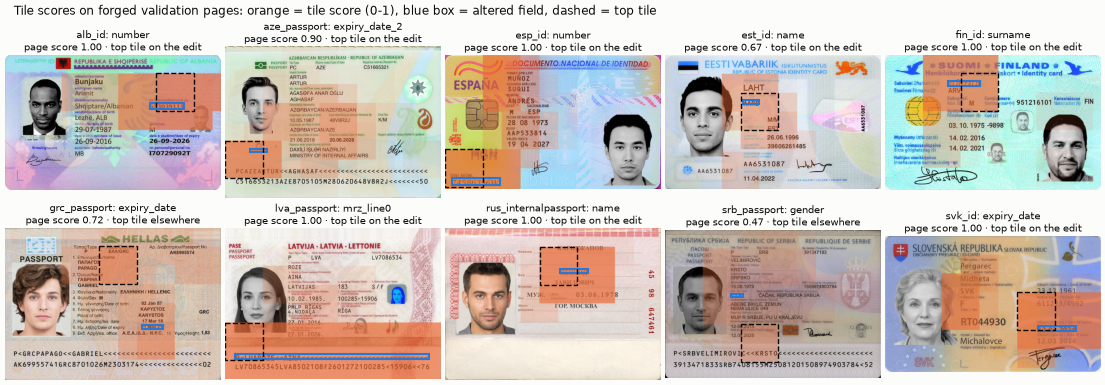

In [16]:
examples = val_pages[val_pages["label"] == 1].sort_values("fake_name").groupby("doc_type").head(1).sort_values("doc_type")
heat_cmap = LinearSegmentedColormap.from_list("heat", [(0.92, 0.41, 0.20, 0.0), (0.92, 0.41, 0.20, 0.7)])
fig, axes = plt.subplots(2, 5, figsize=(22, 7.6), dpi=50, facecolor=SURFACE, layout="constrained")
for ax in axes.flat:
    ax.axis("off")
for ax, (page, row) in zip(axes.flat, examples.iterrows()):
    page_tiles = val_tiles[val_tiles["page"] == page]
    heat = tiles.tile_heatmap(row.hires_width, row.hires_height, page_tiles[["x", "y"]].to_numpy(),
                              page_tiles["score"].to_numpy())
    with Image.open(ROOT / row.hires_path) as image:
        ax.imshow(image)
    ax.imshow(heat, cmap=heat_cmap, vmin=0, vmax=1)
    ax.add_patch(Rectangle((row.edit_x, row.edit_y), row.edit_w, row.edit_h, fill=False, edgecolor=BLUE, linewidth=3))
    top = page_tiles.loc[page_tiles["score"].idxmax()]
    ax.add_patch(Rectangle((top.x, top.y), TILE, TILE, fill=False, edgecolor=INK, linewidth=2, linestyle="--"))
    hit = "top tile on the edit" if top.overlaps_edit else "top tile elsewhere"
    ax.set_title(f"{row.doc_type}: {row.altered_field}\npage score {row.score:.2f} · {hit}", fontsize=14, color=INK)
fig.suptitle("Tile scores on forged validation pages: orange = tile score (0-1), blue box = altered field, "
             "dashed = top tile", x=0.01, ha="left", color=INK, fontsize=17)
fig.savefig(REPORT_DIR / "forgery_v2_heatmaps_val.png", dpi=70, facecolor=SURFACE)
plt.show()

<!-- id: heatmaps -->
PENDING

In [17]:
passed = bool(gate_roc and gate_control)
name = "forgery_detector" if passed else "forgery_detector_v2_rejected"  # a failed model never gets the pipeline name
shutil.copy(MODEL_DIR / checkpoints[choice], MODEL_DIR / f"{name}.keras")
detector_info = {
    "version": "v2: tiles on hi-res templates",
    "status": "passed both validation stop rules" if passed else
              f"REJECTED: document ROC-AUC rule {'passed' if gate_roc else 'failed'}, "
              f"negative control {'passed' if gate_control else 'failed'}",
    "checkpoint": checkpoints[choice],
    "page_preprocessing": f"RGB; resize so the longest side is exactly {LONGEST} px (Lanczos, small pages enlarged); "
                          f"save as JPEG quality {QUALITY}; decode",
    "tile_size": TILE,
    "stride": STRIDE,
    "grid": "starts 0, stride, 2*stride, ... plus one last tile flush with the right/bottom edge (no padding)",
    "tile_input": "float32 pixels 0-255 (EfficientNet rescales internally; do not divide by 255)",
    "tile_output": "sigmoid probability that the tile shows an edited field",
    "aggregation": {"max": "page score = highest tile score",
                    "top3": "page score = mean of the 3 highest tile scores"}[AGGREGATION],
    "decision_rule": "forged if page score >= threshold",
    "thresholds": {"recall_0.90": {k: round(float(v), 4) for k, v in thresholds["recall >= 0.90"].items()},
                   "f1_optimal": {k: round(float(v), 4) for k, v in thresholds["F1-optimal"].items()}},
    "scope": "trained and validated on SIDTD templates (flat scans) only; not validated on photos or video frames",
    "val": {"doc_pr_auc": round(doc_ranking["pr_auc"], 4), "doc_roc_auc": round(doc_ranking["roc_auc"], 4),
            "tile_pr_auc": round(float(tile_ranking.loc[choice, "tile PR-AUC"]), 4),
            "negative_control_auc": round(float(control_auc), 4)},
    "notes": "thresholds were chosen on validation and must be re-checked once on the test split",
}
(MODEL_DIR / f"{name}.json").write_text(json.dumps(detector_info, indent=2))
print(f"saved models/{name}.keras and models/{name}.json")
print(json.dumps(detector_info, indent=2))

saved models/forgery_detector.keras and models/forgery_detector.json
{
  "version": "v2: tiles on hi-res templates",
  "status": "passed both validation stop rules",
  "checkpoint": "forgery_tiles_stage2.keras",
  "page_preprocessing": "RGB; resize so the longest side is exactly 1280 px (Lanczos, small pages enlarged); save as JPEG quality 75; decode",
  "tile_size": 224,
  "stride": 112,
  "grid": "starts 0, stride, 2*stride, ... plus one last tile flush with the right/bottom edge (no padding)",
  "tile_input": "float32 pixels 0-255 (EfficientNet rescales internally; do not divide by 255)",
  "tile_output": "sigmoid probability that the tile shows an edited field",
  "aggregation": "page score = mean of the 3 highest tile scores",
  "decision_rule": "forged if page score >= threshold",
  "thresholds": {
    "recall_0.90": {
      "threshold": 0.7408,
      "precision": 0.9702,
      "recall": 0.9106
    },
    "f1_optimal": {
      "threshold": 0.6646,
      "precision": 0.954,
      

<!-- id: saved -->
PENDING

In [18]:
seconds = {"stage 1": s1_seconds, "stage 2": s2_seconds}
metrics = {
    "split": "validation (test not used)",
    "pages": {s: len(p) for s, p in split_pages.items()},
    "tiles": counts.drop(columns="tiles per page").to_dict(orient="index"),
    "tile_ranking": tile_ranking.round(4).to_dict(orient="index"),
    "checkpoint": choice,
    "aggregation": AGGREGATION,
    "doc_ranking": {k: round(v, 4) for k, v in doc_ranking.items()},
    "thresholds": {rule: {k: round(float(v), 4) for k, v in t.items()} for rule, t in thresholds.items()},
    "negative_control": control.round(4).to_dict(orient="index"),
    "doc_roc_auc_edit_tiles_hidden": round(float(hidden_roc), 4),
    "localisation": localisation.round(4).to_dict(),
    "stop_rules": {"doc_roc_auc": bool(gate_roc), "negative_control": bool(gate_control)},
    "epochs": {k: len(v) for k, v in seconds.items()},
    "mean_epoch_minutes": {k: round(float(np.mean(v)) / 60, 2) for k, v in seconds.items()},
    "peak_memory_gb": round(peak_memory_gb(), 2),
}
(REPORT_DIR / "forgery_v2_metrics_val.json").write_text(json.dumps(metrics, indent=2, default=str))
print(json.dumps({k: metrics[k] for k in ("stop_rules", "epochs", "mean_epoch_minutes", "peak_memory_gb")}, indent=2))
print(f"swap in use now: {swap_used_gb():.1f} GB | notebook run time: {(time.perf_counter() - notebook_start) / 60:.1f} min")
for path in sorted(REPORT_DIR.glob("forgery_v2_*")):
    print(f"  {path.relative_to(ROOT) if path.is_relative_to(ROOT) else path}")

{
  "stop_rules": {
    "doc_roc_auc": true,
    "negative_control": true
  },
  "epochs": {
    "stage 1": 5,
    "stage 2": 10
  },
  "mean_epoch_minutes": {
    "stage 1": 6.13,
    "stage 2": 10.29
  },
  "peak_memory_gb": 12.0
}
swap in use now: 21.0 GB | notebook run time: 139.6 min
  reports/phase3/forgery_v2_breakdown_altered_field_val.csv
  reports/phase3/forgery_v2_breakdown_ctype_val.csv
  reports/phase3/forgery_v2_breakdown_doc_type_val.csv
  reports/phase3/forgery_v2_heatmaps_val.png
  reports/phase3/forgery_v2_localisation_val.csv
  reports/phase3/forgery_v2_metrics_val.json
  reports/phase3/forgery_v2_negative_control.png
  reports/phase3/forgery_v2_pr_roc_val.png
  reports/phase3/forgery_v2_stage1_log.csv
  reports/phase3/forgery_v2_stage2_log.csv
  reports/phase3/forgery_v2_thresholds_val.csv
  reports/phase3/forgery_v2_tiles_check.png
  reports/phase3/forgery_v2_training_curves.png


<!-- id: summary -->
PENDING